In [84]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Earthq_4.5up_last30.csv')
print(df.head())

                       time  latitude  longitude    depth  mag magType  nst  \
0  2026-11-08T20:16:30.347Z   38.3782   141.9370   55.699  4.5     mwr   83   
1  2026-11-08T16:45:12.938Z    2.5497   128.6755  224.590  4.6      mb   51   
2  2026-11-08T16:33:24.915Z    7.7030   -36.9451   10.000  4.8      mb   25   
3  2026-11-08T12:29:17.722Z  -27.6901    64.4430   10.000  4.7      mb   40   
4  2026-11-08T11:58:32.451Z  -19.6811   -70.0603   68.785  4.7     mwr   36   

   gap    dmin   rms  ...                   updated  \
0  131   2.501  0.64  ...  2026-11-08T20:36:23.040Z   
1   80   5.448  0.86  ...  2026-11-08T17:04:06.040Z   
2  110  13.480  1.03  ...  2026-11-08T17:20:59.040Z   
3  111   7.959  0.67  ...  2026-11-08T12:51:23.040Z   
4  140   0.590  0.67  ...  2026-11-08T16:09:13.957Z   

                            place        type horizontalError depthError  \
0   43 km E of Onagawa Chō, Japan  earthquake            7.95      6.112   
1  117 km NE of Tobelo, Indonesia  earthqu

In [85]:
#print(df.columns)
#print(df['type'].value_counts())
columns = ['time', 'latitude', 'longitude', 'depth', 'mag', 'place', 'type']
print(df[columns].head())

                       time  latitude  longitude    depth  mag  \
0  2026-11-08T20:16:30.347Z   38.3782   141.9370   55.699  4.5   
1  2026-11-08T16:45:12.938Z    2.5497   128.6755  224.590  4.6   
2  2026-11-08T16:33:24.915Z    7.7030   -36.9451   10.000  4.8   
3  2026-11-08T12:29:17.722Z  -27.6901    64.4430   10.000  4.7   
4  2026-11-08T11:58:32.451Z  -19.6811   -70.0603   68.785  4.7   

                            place        type  
0   43 km E of Onagawa Chō, Japan  earthquake  
1  117 km NE of Tobelo, Indonesia  earthquake  
2      central Mid-Atlantic Ridge  earthquake  
3          Southwest Indian Ridge  earthquake  
4        46 km NW of Huara, Chile  earthquake  


**Time:** Date and time the earthquake happened

**Latitude:** Where the earthquake happened geographically (latitudinally)

**Longitude:** Where the earthquake happened geographically (longitudinally)

**Depth:** how deep the earthquake occured (in km)

**Magnitude (mag):** the magnitude of the earthquake

**Place:** the name of the location of the earthquake

**Type:** the type of event

In [86]:
#3A display first rows + identify # of records, check important columns for missing val [done]

#3b tot num of eq, avg mag, lrgst mag, smlst mag, avg depth, shallowest depth [done]

#3c func to assign each eq to a mag category, clearly state limits and applt to dataset [done]

#3d shallow (<70km) intermediate(70<x<300) or deep(>300km) [done]

#3e how many eq in each mag cat and dep cat [done]

#3f identify mag >= 5 and explain why useful

#3g extreme; print lrgst mag eq and deepest eq

#3h reusable func; write three user def at least one w if/else

In [87]:
tot_eq = len(df)
avg_mag = df['mag'].mean()
max_mag = df['mag'].max()
min_mag = df['mag'].min()
avg_depth = df['depth'].mean()
max_dep = df['depth'].max()
min_dep = df['depth'].min()
missing_val = df[columns].isnull().sum()

print("Tot earthquakes:", tot_eq)
print("Avg mag:", avg_mag)
print("Largest mag:", max_mag)
print("Smallest mag:", min_mag)
print("Average depth:", avg_depth)
print("Deepest earthquake:", max_dep, "km")
print("Shallowest earthquke:", min_dep, "km")

print("\nMissing values:\n", missing_val)


Tot earthquakes: 759
Avg mag: 4.850522991246747
Largest mag: 7.7
Smallest mag: 4.5
Average depth: 55.87990513833992
Deepest earthquake: 642.624 km
Shallowest earthquke: 1.0 km

Missing values:
 time         0
latitude     0
longitude    0
depth        0
mag          0
place        0
type         0
dtype: int64


In [88]:
def mag_class(mag):
  if mag < 5:
    return "light"
  elif mag < 6:
    return "moderate"
  elif mag < 7:
    return "strong"
  elif mag < 8:
    return "major"
  else:
    return "great"

In [89]:
df['mag_category'] = df['mag'].apply(mag_class)
#print('Magnitudes (by cat):', df['mag_category'].value_counts())

In [90]:
def depth_class(depth):
  if depth < 70:
    return "shallow"
  elif depth <=300:
    return "intermediate"
  else:
    return "deep"

In [91]:
df['depth_category'] = df['depth'].apply(depth_class)
#print('Depths (by cat):', df['depth_category'].value_counts())

In [92]:
print('Magnitudes (by cat):', df['mag_category'].value_counts())
print('\nDepths (by cat):', df['depth_category'].value_counts())

Magnitudes (by cat): mag_category
light       549
moderate    187
strong       21
major         2
Name: count, dtype: int64

Depths (by cat): depth_category
shallow         608
intermediate    116
deep             35
Name: count, dtype: int64


In [93]:
#3f
def mag_over5(mag):
  if mag >= 5:
    return True
  else:
    return False

In [94]:
df['mag_over5'] = df['mag'].apply(mag_over5)
print("Earthquakes with impact on engineering(mag over 5.0):", df['mag_over5'].sum())

Earthquakes with impact on engineering(mag over 5.0): 210


i chose to filter for eqs (earthquakes) with magnitudes of 5.0 and above because stronger eqs have a greater potential to cause damage to buildings and infrastructure, impacting human lives. Of the 759 eqs in the dataset, 210 met this condition

In [95]:
print("Largest-mag earthquake:")
print(df.loc[df['mag'].idxmax(), ['time', 'place', 'mag', 'depth']])

Largest-mag earthquake:
time                 2026-10-09T17:56:05.537Z
place    10 km WSW of Pitaloza Arriba, Panama
mag                                       7.7
depth                                    10.0
Name: 741, dtype: object


In [96]:
print("Deepest earthquake:")
print(df.loc[df['depth'].idxmax(), ['time', 'place', 'mag', 'depth']])

Deepest earthquake:
time     2026-10-09T08:27:10.319Z
place    101 km E of Levuka, Fiji
mag                           4.8
depth                     642.624
Name: 753, dtype: object


In [97]:
#4a histogram of mags
#4b scatterplot mag v dep
#4c bar chat num eq per mag cat
#4d location based plot

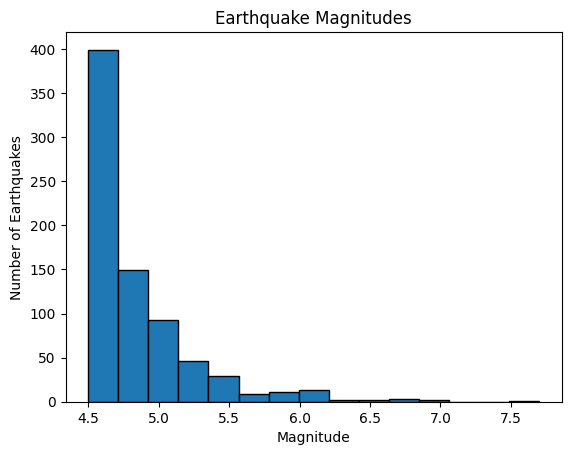

In [98]:
#4a
plt.hist(df['mag'], bins=15, edgecolor='black')
plt.title("Earthquake Magnitudes")
plt.xlabel("Magnitude")
plt.ylabel("Number of Earthquakes")
plt.show()

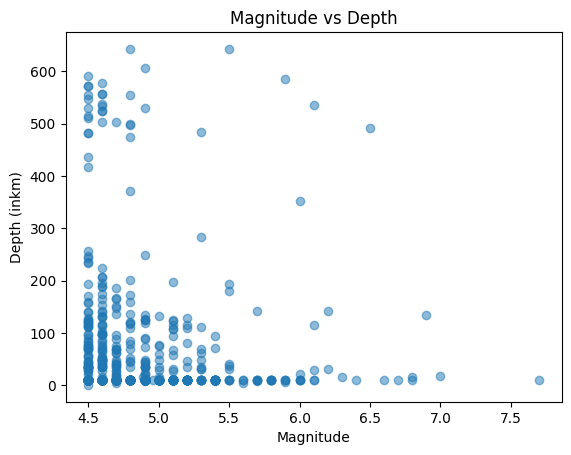

In [101]:
#4b scatterplot mag v dep
plt.scatter(df['mag'], df['depth'], alpha=0.5)
plt.title("Magnitude vs Depth")
plt.xlabel("Magnitude")
plt.ylabel("Depth (inkm)")
plt.show()


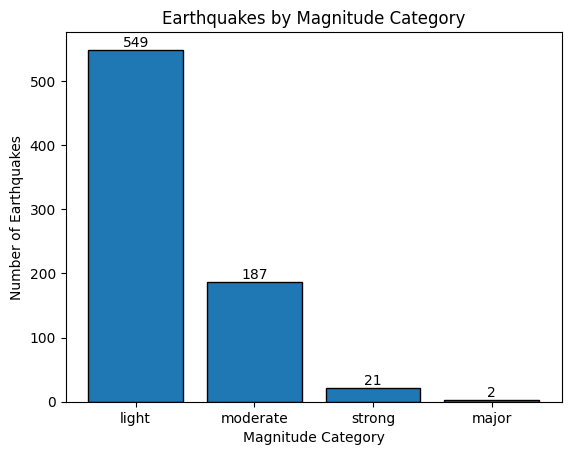

In [104]:
#44c
mag_counts = df['mag_category'].value_counts()
plt.bar(mag_counts.index, mag_counts.values, edgecolor='black')

for i in range(len(mag_counts)):
  plt.text(i, mag_counts.iloc[i] + 5, mag_counts.iloc[i], ha='center')

plt.title("Earthquakes by Magnitude Category")
plt.xlabel("Magnitude Category")
plt.ylabel("Number of Earthquakes")
plt.show()


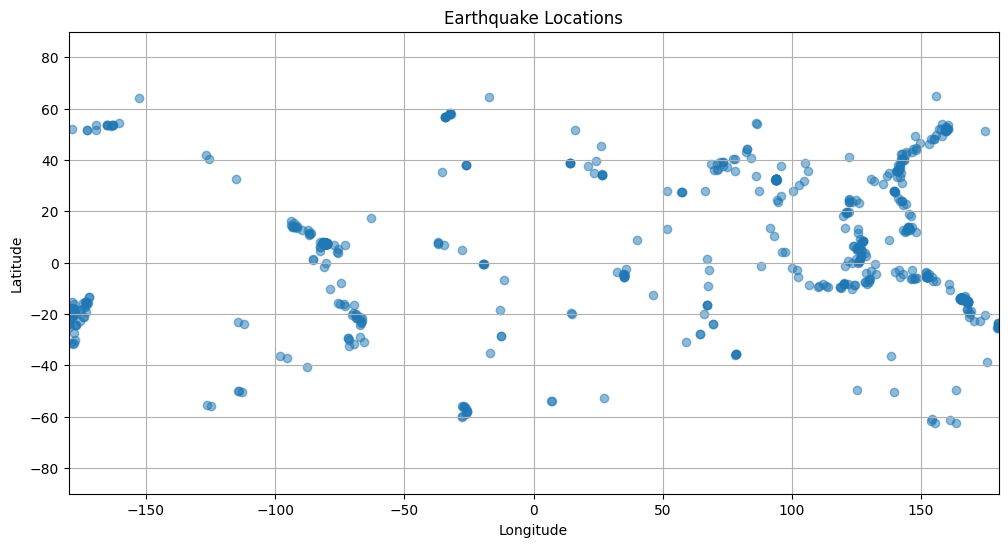

In [105]:
#4d location based plot
plt.figure(figsize=(12, 6))

plt.scatter(df['longitude'], df['latitude'], alpha=0.5)

plt.title("Earthquake Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True)
plt.show()


In [107]:
major_eq = df[df['mag_category'] == 'major']
print(major_eq[['time', 'place', 'mag', 'depth', 'latitude', 'longitude']].to_string(index=False))


                    time                                place  mag  depth  latitude  longitude
2026-10-22T14:33:40.289Z           189 km ENE of Nagqu, China  7.0   18.0   32.3376    93.7837
2026-10-09T17:56:05.537Z 10 km WSW of Pitaloza Arriba, Panama  7.7   10.0    7.6069   -80.7566


1. **Which magnitude range occurs most frequently in your dataset?**
*   549/759 of all the eq in the dataset were in the range 5.0 to 4.5 (under 5.0)

2. **Are most earthquakes shallow, intermediate, or deep?**
*   most were shallow, 608/759. there were only 116 intermediate, and 35 deep eqs
3. **Do you observe a clear relationship between magnitude and depth? Explain.**
*   as most eqs occur at the surface and most are under 5.0, it is hard to say. but you the data does seem to sugges that more weaker eqs occur at lower depths than stronger ones.

4. **Which event in your dataset appears most important from an engineering perspective, and why?**
*   I would say the two major earthquakes that occureed are most impactful from an engineering perspective because of their potentially damaging effects on infratructure and resulting danger to human lives. of the two, i'd estimate that the one by Arriba in Panama would have a greater impact since its proximity, whereas the one in China is further away

5. **Why can both earthquake magnitude and depth matter for structural or infrastructure engineering?**
*   mag matters because stronger eqs cause more damage to structures, thereby impacting the people in those structures. repeated earthquakes will take their toll, as will stronger devastating ones.
*   depth matters because if the eq is towards the surface, it would probably have a more direct impact and cause more damage to structures than a deeper one would otherwise

6. **What is one limitation of your dataset or analysis?**
*   i chose to export and utilize a dataset from the past month of eqs of mags 4.5 or greater. this is an extremely limited dataset in the grand scheme of things, not giving a full picture as to the the longer term eq patterns and the impact of weaker eqs

7. **What additional data would you want if you were performing a more complete earthquake-engineering study?**
*   i would chose to do a longer period w weaker eqs. i would also like to pay closer attention to the damage done somehow